# P17: can the guide tell when it is not sure?

P10 found that 29 of the final model's 80 validation mistakes were made with a confidence above 0.8, and that the true genre
is its first or second choice for 95% of the paintings. A guide that tells a visitor the wrong story with confidence is worse
than one that says "this is a portrait or a religious painting". Two questions:

1. **Calibration.** When the model says 0.9, is it right 90% of the time? Measured with the **expected calibration error**
   (ECE: the paintings are grouped by confidence in 15 bins of equal width; in each bin, the gap between the mean confidence
   and the accuracy, weighted by the share of paintings in the bin). The usual repair is **temperature scaling**: divide the
   scores by one number T before the softmax, chosen to minimise the loss on validation. It never changes the predicted genre,
   only how sure the model claims to be.
2. **Abstention.** Below a confidence threshold, the guide gives its two best genres instead of one.

**The rules, fixed before any result** (a scratch run, unsaved, checked the code):

- The final model (ADR 0012) is not changed or retrained. T is fitted on validation; the ECE on validation after scaling is
  measured by **2-fold cross-fitting** (T fitted on one half of the validation paintings, measured on the other, and the
  other way round), so it is not measured on the paintings that chose T.
- **The threshold** is the lowest confidence (after scaling) at which the paintings the guide answers alone are right at
  least **95%** of the time on validation. Below it, the guide shows its two best genres.
- **Museum B once:** the ECE before and after scaling, and the share answered alone, their accuracy and the top-2 accuracy of
  the others, with T and the threshold chosen on validation. The predictions themselves were already scored (86.0%,
  ADR 0012); this only measures confidence. T and the threshold go to `results/confidence.json`, for the demo.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from deep_learning_project_waerniers_lamy_mahieddine.vision.utils import (
    PERTURBATIONS, RESULTS_DIR, final_model, perturb, predict_logits, split_images)

model = final_model()
val_images, val_labels = split_images("val")
val_logits = predict_logits(model, val_images)
print(f"final model, validation accuracy {(val_logits.argmax(1) == val_labels).float().mean():.1%} (ADR 0012: 83.3%)")


def ece(probs, labels, bins=15):
    """Expected calibration error: in bins of equal width of the top confidence, the gap |accuracy - mean confidence|,
    weighted by the share of paintings in each bin."""
    confidence, predicted = probs.max(dim=1)
    correct = (predicted == labels).float()
    edges = torch.linspace(0, 1, bins + 1)
    error = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        inside = (confidence > low) & (confidence <= high)
        if inside.any():
            error += inside.float().mean() * (correct[inside].mean() - confidence[inside].mean()).abs()
    return float(error)


def fit_temperature(logits, labels):
    """The temperature T that minimises the cross-entropy of softmax(logits / T) on these paintings (LBFGS on log T)."""
    log_t = torch.zeros(1, requires_grad=True)
    optimizer = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)
    loss_fn = torch.nn.CrossEntropyLoss()

    def closure():
        optimizer.zero_grad()
        loss = loss_fn(logits / log_t.exp(), labels)
        loss.backward()
        return loss

    optimizer.step(closure)
    return log_t.exp().item()


def nll(logits, labels, t=1.0):
    return torch.nn.functional.cross_entropy(logits / t, labels).item()

final model, validation accuracy 83.3% (ADR 0012: 83.3%)


## 1. Calibration and temperature scaling

In [2]:
before = ece(val_logits.softmax(1), val_labels)
order = torch.randperm(len(val_labels), generator=torch.Generator().manual_seed(0))
halves = [order[: len(order) // 2], order[len(order) // 2:]]
crossfit_ece, crossfit_t = [], []
for fit_half, eval_half in [(0, 1), (1, 0)]:
    t = fit_temperature(val_logits[halves[fit_half]], val_labels[halves[fit_half]])
    crossfit_t.append(t)
    crossfit_ece.append(ece((val_logits[halves[eval_half]] / t).softmax(1), val_labels[halves[eval_half]]))
T = fit_temperature(val_logits, val_labels)

mistakes = val_logits.argmax(1) != val_labels
confident_before = (val_logits.softmax(1).max(1).values[mistakes] > 0.8).sum().item()
confident_after = ((val_logits / T).softmax(1).max(1).values[mistakes] > 0.8).sum().item()
print(f"temperature fitted on all of validation: T = {T:.2f} (on each half: {crossfit_t[0]:.2f} and {crossfit_t[1]:.2f})")
print(f"validation ECE: before {before:.3f} | after, cross-fitted {np.mean(crossfit_ece):.3f} (halves {crossfit_ece[0]:.3f}, {crossfit_ece[1]:.3f})")
print(f"validation loss: before {nll(val_logits, val_labels):.3f}, after {nll(val_logits, val_labels, T):.3f}")
print(f"mistakes made with a confidence above 0.8: {confident_before} of {mistakes.sum().item()} before, {confident_after} after")

temperature fitted on all of validation: T = 1.23 (on each half: 1.27 and 1.18)
validation ECE: before 0.061 | after, cross-fitted 0.068 (halves 0.069, 0.067)
validation loss: before 0.475, after 0.463
mistakes made with a confidence above 0.8: 29 of 80 before, 22 after


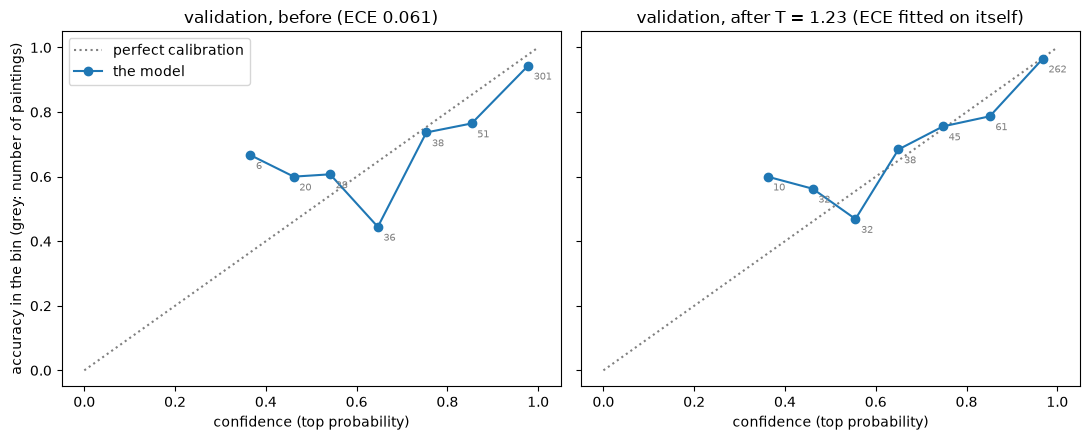

In [3]:
def reliability(ax, probs, labels, title, bins=10):
    confidence, predicted = probs.max(dim=1)
    correct = (predicted == labels).float()
    edges = np.linspace(0, 1, bins + 1)
    centres, accuracies, counts = [], [], []
    for low, high in zip(edges[:-1], edges[1:]):
        inside = (confidence > low) & (confidence <= high)
        if inside.sum() > 0:
            centres.append(confidence[inside].mean().item())
            accuracies.append(correct[inside].mean().item())
            counts.append(inside.sum().item())
    ax.plot([0, 1], [0, 1], color="grey", linestyle=":", label="perfect calibration")
    ax.plot(centres, accuracies, marker="o", color="tab:blue", label="the model")
    for x, y, n in zip(centres, accuracies, counts):
        ax.annotate(str(n), (x, y), textcoords="offset points", xytext=(4, -10), fontsize=7, color="grey")
    ax.set_xlabel("confidence (top probability)")
    ax.set_title(title)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
reliability(axes[0], val_logits.softmax(1), val_labels, f"validation, before (ECE {before:.3f})")
reliability(axes[1], (val_logits / T).softmax(1), val_labels, f"validation, after T = {T:.2f} (ECE fitted on itself)")
axes[0].set_ylabel("accuracy in the bin (grey: number of paintings)")
axes[0].legend()
plt.tight_layout()
plt.show()

**What we see.**

- **The model is already fairly well calibrated:** ECE 0.061 on validation. Its 301 most confident paintings (confidence about 0.98) are right 94% of the time; the middle bins hold 20 to 50 paintings each and swing around the diagonal.
- **T = 1.23** (1.27 and 1.18 on the two halves): above 1, so the model is slightly over-confident, and scaling softens it. The validation loss drops from 0.475 to 0.463, and the mistakes made with a confidence above 0.8 go from 29 to 22 out of 80.
- **But the cross-fitted ECE does not improve:** 0.068 against 0.061 before. With 240 paintings per half, the ECE moves by about as much as temperature scaling can fix. On validation, temperature scaling is a small, harmless change, not a measurable repair.